# Configuración de la radio definida por Software

In [9]:
#------------------------------- Libraries ------------------------------- 
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, spectrogram

## Crear señal y metodos de deteccion


In [10]:
#------------------- LoRa preamble transmitter/receiver -------------------
SF_LORA = 8
BW_LORA = float(2_000_000)
FS_LORA = float(2_000_000)
N_LORA = int(2**SF_LORA)
k_lora = np.arange(N_LORA)

mensaje = 'hola mundo'
bytes_enviados = mensaje.encode('ascii')

def modular_simbolo(valor):
    if not 0 <= valor < N_LORA:
        raise ValueError('Símbolo fuera de rango')
    fase_discreta = ((valor+k_lora) % N_LORA)*k_lora/N_LORA
    return np.exp(2j*np.pi*fase_discreta)/np.sqrt(N_LORA)


# 8 símbolos completos ascendentes + 2 símbolos y 1/4 descendentes.
upchirp_lora = np.exp(1j * 2 * np.pi * k_lora**2 / N_LORA)
downchirp_lora = np.conj(upchirp_lora)
tx_preamble = np.concatenate([
    *([upchirp_lora] * 8),
    downchirp_lora,
    downchirp_lora,
    downchirp_lora[:N_LORA // 4],
])
# payload 10 simbolos en modulacion lora 'hola mundo'
payload = np.concatenate([modular_simbolo(v) for v in bytes_enviados])
silencio = np.zeros(N_LORA) # 1 simbolo de silencio antes y dps de trama
# juntar todo en misma señal y normalizar
tx_signal = np.concatenate([tx_preamble, payload])
tx_signal = tx_signal / np.max(np.abs(tx_signal))
tx_signal = np.concatenate([silencio, tx_signal, silencio])
print(f'Preambulo: 8 upchirps + 2.25 downchirps + 10 simbolos payload; N={N_LORA} muestras/simbolo; {len(tx_preamble)} muestras')
# GRAFICAR esto

def _chirp_peak_ratio(segmento, referencia):
    espectro = np.fft.fft(segmento * np.conj(referencia))
    potencia = np.abs(espectro)**2
    return float(np.max(potencia) / (np.mean(potencia) + np.finfo(float).eps))

def detectar_preambulo_lora(rx, upchirp, downchirp, n_up=8):
    n = len(upchirp)
    longitud = n * (n_up + 2) + n // 4
    if len(rx) < longitud:
        raise ValueError('La captura no contiene suficientes muestras para el preámbulo')

    # Se prueban todas las fases de símbolo; así no se exige sincronismo externo.
    mejor_inicio, mejor_puntaje = None, -np.inf
    for inicio in range(n):
        up_scores = [
            _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], upchirp)
            for i in range(n_up)
        ]
        down_scores = [
            _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], downchirp)
            for i in range(n_up, n_up + 2)
        ]
        puntaje = float(np.mean(up_scores) + np.mean(down_scores))
        if puntaje > mejor_puntaje:
            mejor_inicio, mejor_puntaje = inicio, puntaje

    inicio = int(mejor_inicio)
    up_scores = np.array([
        _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], upchirp)
        for i in range(n_up)
    ])
    down_scores = np.array([
        _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], downchirp)
        for i in range(n_up, n_up + 2)
    ])
    cuarto_down = rx[inicio + (n_up + 2)*n:inicio + longitud]
    cuarto_score = _chirp_peak_ratio(cuarto_down, downchirp[:n // 4])
    detectado = (np.mean(up_scores) > 5) and (np.mean(down_scores) > 5) and (cuarto_score > 1)
    return {
        'detectado': bool(detectado),
        'inicio_muestra': inicio,
        'puntaje_upchirps': up_scores,
        'puntaje_downchirps': down_scores,
        'puntaje_downchirp_1_4': cuarto_score,
    }



Preambulo: 8 upchirps + 2.25 downchirps + 10 simbolos payload; N=256 muestras/simbolo; 2624 muestras


## Transmisión y detección del preámbulo LoRa

El bloque siguiente genera 8 *upchirps* y 2,25 *downchirps*, los transmite y busca el preámbulo en la captura mediante *dechirp* y FFT. Para una prueba digital local usar `Loopback = 1`; para una prueba por RF usar `Loopback = 0`.

## 3. CONF, MANDAR Y RECIBIR CON SDR


In [11]:
import adi
sdr = adi.Pluto('ip:192.168.1.34')
sdr.tx_destroy_buffer()
sdr.rx_destroy_buffer()
sdr.loopback = 0
# Esta tasa fija la duración física de cada muestra, tanto en TX como en RX.
sdr.sample_rate = FS_LORA # 2MS/s
sdr.tx_lo = 915_000_000
sdr.rx_lo = 915_000_000
sdr.tx_rf_bandwidth = 2_000_000
sdr.rx_rf_bandwidth = 2_000_000
sdr.tx_hardwaregain_chan0 = -50
sdr.gain_control_mode_chan0 = 'slow_attack'
sdr.rx_buffer_size = 2*len(tx_signal)
sdr.tx_cyclic_buffer = True
# sdr._ctrl.context.set_timeout(0) # <- disable timeout if you want to use large buffer size


In [12]:
# TRANSMITIR
# `sdr.tx()` toma el tamaño del buffer TX de este vector de 6208 muestras.
muestras_sdr = (tx_signal * (2**15-1)).astype(np.complex64)
rx_signal = None  # Una falla de TX invalida cualquier captura anterior del kernel.
print(f'TX preparado: {len(muestras_sdr)} muestras, primera y ultimas {N_LORA} son silencio')
sdr.tx_destroy_buffer()
sdr.tx(muestras_sdr)


TX preparado: 5696 muestras, primera y ultimas 256 son silencio


In [13]:
rx_signal = np.asarray(sdr.rx()).copy()
print('Muestras RX en memoria:', len(rx_signal))

Muestras RX en memoria: 11392


In [14]:
# CERRAR SDR
sdr.tx_destroy_buffer()
sdr.tx_hardwaregain_chan0 = -89
sdr.tx_lo = int(2400e6)
sdr.rx_lo = int(950e6)
sdr.tx(np.zeros(2048))
del sdr


## Ahora detecto inicio de señal recibida

In [15]:

resultado_preambulo = detectar_preambulo_lora(
    rx_signal, upchirp_lora, downchirp_lora
)
print('Preambulo detectado:', resultado_preambulo['detectado'])
print('Inicio estimado:', resultado_preambulo['inicio_muestra'])
print('Picos upchirp:', np.round(resultado_preambulo['puntaje_upchirps'], 1))
print('Picos downchirp:', np.round(resultado_preambulo['puntaje_downchirps'], 1))
print('Pico downchirp 1/4:', round(resultado_preambulo['puntaje_downchirp_1_4'], 1))

Preambulo detectado: False
Inicio estimado: 0
Picos upchirp: [225.7 182.5  47.7 226.2 226.2 226.2 226.3  79.7]
Picos downchirp: [4.3 4.5]
Pico downchirp 1/4: 2.4


## Gráficos de la señal enviada y recibida

Se muestran las componentes I/Q, el espectro, la frecuencia instantánea y los primeros símbolos de la ráfaga transmitida y de la captura recibida.

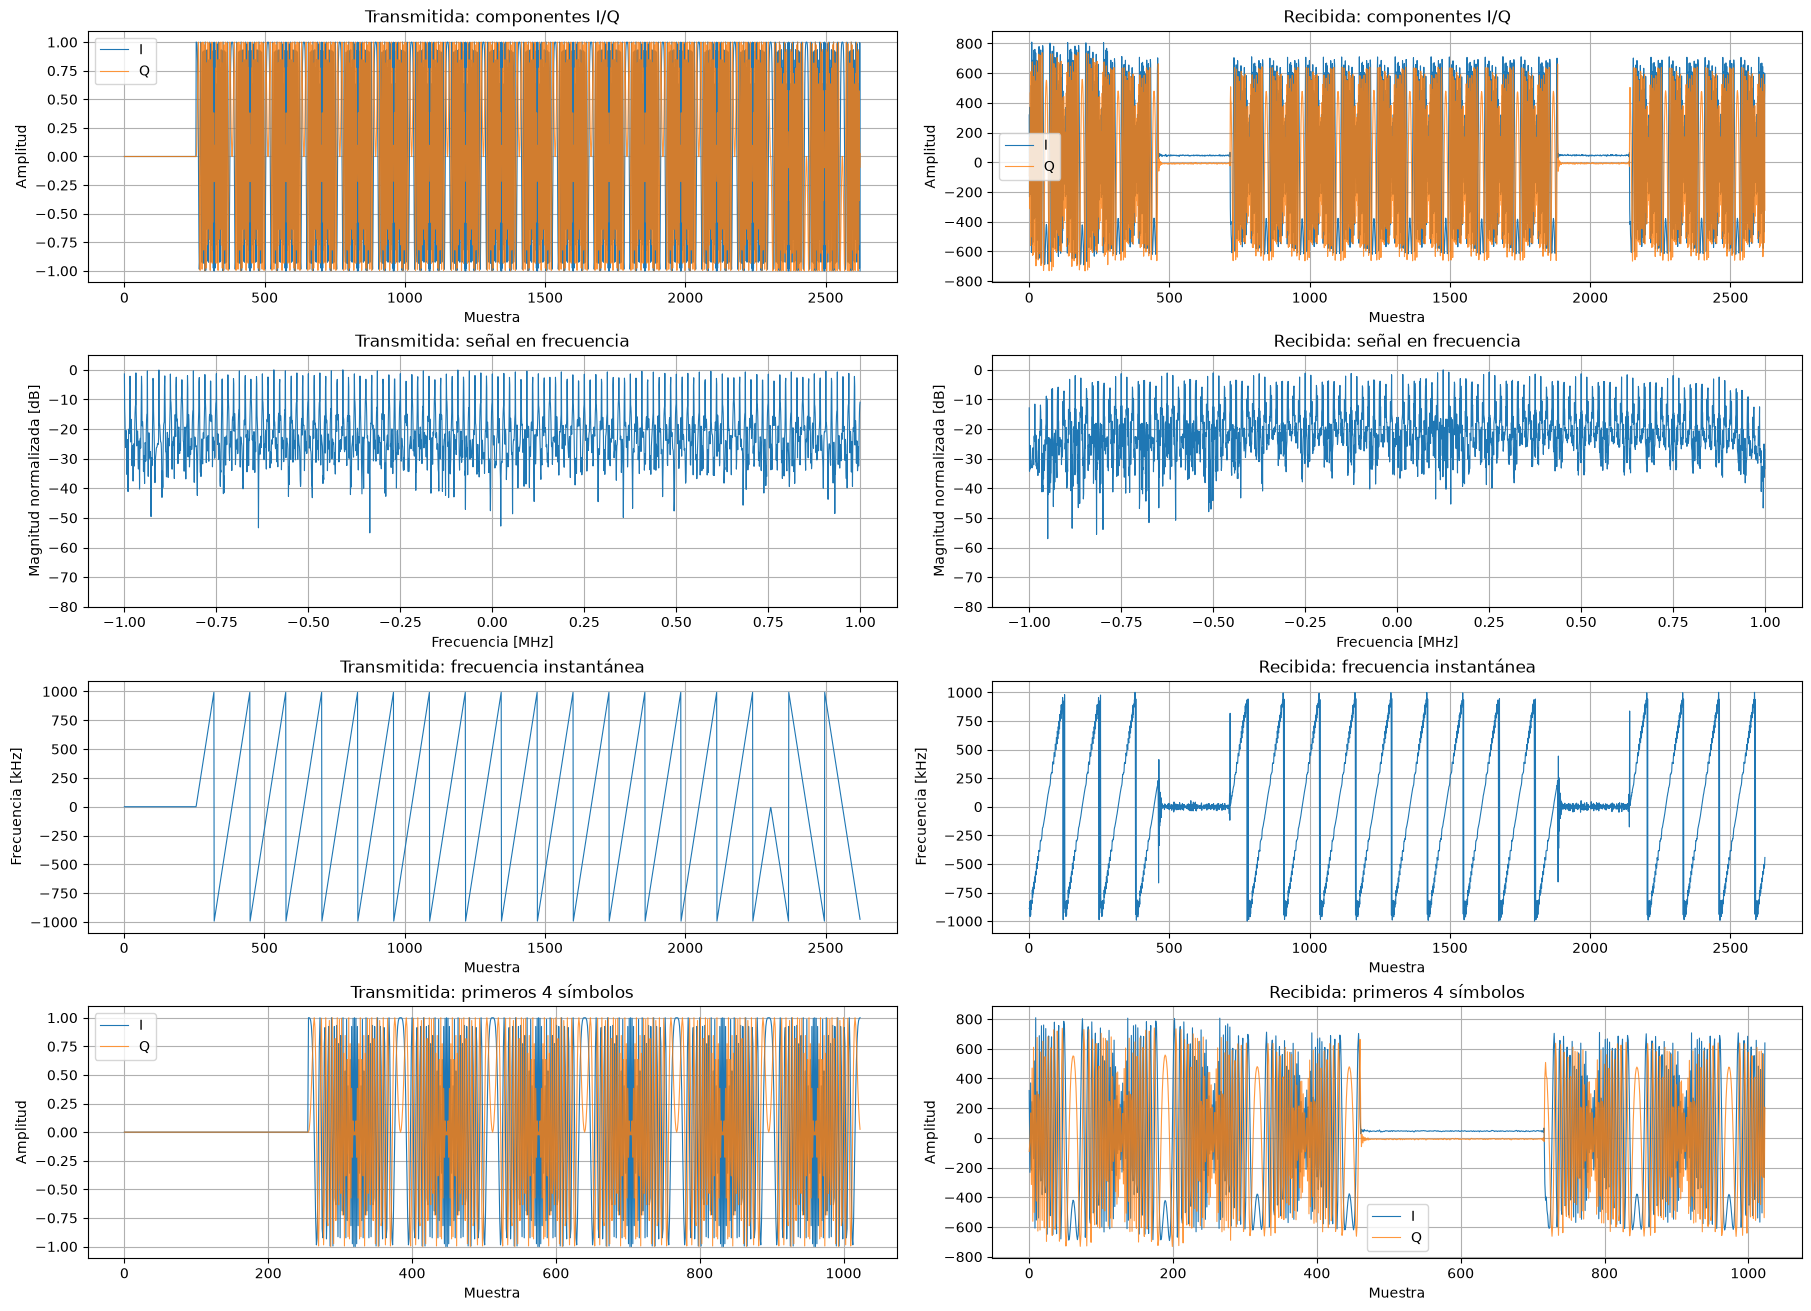

In [16]:
def graficar_preambulo_lora(tx, rx, fs, inicio=0, n_muestras=0):
    if n_muestras <= 0:
        n_muestras = min(len(tx), len(rx) - inicio)
    tx_vista = np.asarray(tx[:n_muestras], dtype=complex)
    rx_vista = np.asarray(rx[inicio:inicio + n_muestras], dtype=complex)
    n_fft = max(len(tx_vista), len(rx_vista))
    frecuencia = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / fs)) / 1e6

    fig, ax = plt.subplots(4, 2, figsize=(18, 13), constrained_layout=True)
    señales = ((tx_vista, 'Transmitida'), (rx_vista, 'Recibida'))
    for columna, (senal, etiqueta) in enumerate(señales):
        muestras = np.arange(len(senal))
        ax[0, columna].plot(muestras, np.real(senal), label='I', linewidth=0.8)
        ax[0, columna].plot(muestras, np.imag(senal), label='Q', linewidth=0.8, alpha=0.8)
        ax[0, columna].set_title(f'{etiqueta}: componentes I/Q')
        ax[0, columna].set_xlabel('Muestra')
        ax[0, columna].set_ylabel('Amplitud')
        ax[0, columna].legend()
        ax[0, columna].grid()

        espectro = np.fft.fftshift(np.fft.fft(senal, n=n_fft))
        magnitud = np.abs(espectro)
        espectro_db = 20 * np.log10(magnitud / (np.max(magnitud) + np.finfo(float).eps) + np.finfo(float).eps)
        ax[1, columna].plot(frecuencia, espectro_db, linewidth=0.8)
        ax[1, columna].set_title(f'{etiqueta}: señal en frecuencia')
        ax[1, columna].set_xlabel('Frecuencia [MHz]')
        ax[1, columna].set_ylabel('Magnitud normalizada [dB]')
        ax[1, columna].set_ylim(-80, 5)
        ax[1, columna].grid()

        fase = np.unwrap(np.angle(senal))
        frecuencia_instantanea = np.diff(fase) * fs / (2 * np.pi)
        ax[2, columna].plot(muestras[1:], frecuencia_instantanea / 1e3, linewidth=0.8)
        ax[2, columna].set_title(f'{etiqueta}: frecuencia instantánea')
        ax[2, columna].set_xlabel('Muestra')
        ax[2, columna].set_ylabel('Frecuencia [kHz]')
        ax[2, columna].grid()

        n_primeros = min(len(muestras), 4 * N_LORA)
        ax[3, columna].plot(muestras[:n_primeros], np.real(senal[:n_primeros]), label='I', linewidth=0.8)
        ax[3, columna].plot(muestras[:n_primeros], np.imag(senal[:n_primeros]), label='Q', linewidth=0.8, alpha=0.8)
        ax[3, columna].set_title(f'{etiqueta}: primeros 4 símbolos')
        ax[3, columna].set_xlabel('Muestra')
        ax[3, columna].set_ylabel('Amplitud')
        ax[3, columna].legend()
        ax[3, columna].grid()
    plt.show()

graficar_preambulo_lora(
    tx_signal,
    rx_signal,
    FS_LORA,
    inicio=resultado_preambulo['inicio_muestra'],
    n_muestras=len(tx_preamble),
)